<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


<h1>Fashion-MNIST Project </h1>


## AI assistance and execution scope

AI-assisted solution to the original IBM course notebook. The original tasks and both model constructors are retained. No independent authorship or personal learning experience is claimed. All displayed results must come from actual execution.

This run uses all 60,000 training images and all 10,000 images in the official test split, which the course calls validation. Images are resized to 16x16 because two 2x2 pooling stages must produce the 4x4 map expected by the supplied classifier. The BatchNorm constructor is selected, with batch size 100, SGD learning rate 0.1 and exactly five epochs. Training is shuffled reproducibly with seed 0. No test-driven architecture or epoch search is performed.

Evaluation after each epoch follows the course exercise; this repeatedly viewed split is not a fresh independent test for a future deployed model. Five epochs and the original small architecture are an instructional experiment, not a production-quality guarantee.

**Estimated Time Needed**: 30 min


<h2>Table of Contents</h2>


<p>In this project, you will classify  Fashion-MNIST dataset using convolutional neural networks.</p>
<ul>
  
<ol>
<li><a href="#Prepare-the-Lab-Environment">Prepare the Lab Environment</a> 
</li>
<li><a href="#Task-1:-Create-a-Dataset-Class">Task 1: Create a Dataset Class</a>
</li> 
 <li><a href="#Task-2:-Build-and-Train-a-Convolutional-Neural-Network"> Task 2: Build and Train a Convolutional Neural Network</a>
<ol>

</ul>


## Prepare the Lab Environment


Download the datasets you needed for this lab.


The following are the PyTorch modules you are going to need:


In [1]:
# Packages are installed once in the course terminal, rather than upgraded on each run.
# Reproduce with torch==2.8.0+cpu torchvision==0.23.0+cpu from the official CPU index:
# https://download.pytorch.org/whl/cpu
# Supporting packages: numpy==1.26.4, matplotlib==3.10.9, Pillow==12.3.0,
# nbformat and nbclient. The original environment needed its pip upgraded first.
import sys, json, time, random, hashlib, platform
from pathlib import Path
from importlib.metadata import version
print('Python:', platform.python_version())
print({p: version(p) for p in ['torch', 'torchvision', 'numpy', 'matplotlib', 'Pillow']})


Python: 3.10.11
{'torch': '2.8.0+cpu', 'torchvision': '0.23.0+cpu', 'numpy': '1.26.4', 'matplotlib': '3.10.9', 'Pillow': '12.3.0'}


In [2]:
# The original optional installation cell is intentionally not rerun.
print('AI assistance is disclosed. Training outputs below are generated by actual execution.')


AI assistance is disclosed. Training outputs below are generated by actual execution.


In [3]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision
import torchvision.datasets as dsets
import torch
import torch.nn as nn
import numpy as np
from IPython.display import display, Markdown

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
device = torch.device('cpu')
OUT = Path('fashion_outputs')
OUT.mkdir(exist_ok=True)
print('Device:', device, 'seed:', SEED, 'CPU threads:', torch.get_num_threads())


Device: cpu seed: 0 CPU threads: 2


Import the non-PyTorch modules: 


In [4]:
from matplotlib.pyplot import imshow
import matplotlib.pyplot as plt
from PIL import Image


In [5]:
def show_data(data_sample):
    image, label = data_sample
    plt.imshow(image.numpy().reshape(IMAGE_SIZE, IMAGE_SIZE), cmap='gray', vmin=0, vmax=1)
    plt.title(f'y = {label}: {dataset_val.classes[label]}')
    plt.axis('off')


<hr>


## Task 1: Create a Dataset Class


In this section, you will load a Dataset object, but first you must transform the dataset. Use the <code>Compose</code> function to perform the following transforms:. 
<ol>
    <li>Use the transforms object to<code> Resize </code> to resize the image.</li>
    <li>Use the transforms object to<code> ToTensor </code> to convert the image to a tensor.</li>
</ol>

You will then take a screen shot of your validation data.


Use the Compose function to compose the transforms


In [6]:
# Two 2x2 pooling stages turn a 16x16 input into the required 4x4 feature map.
IMAGE_SIZE = 16
composed = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])
print(composed)


Compose(
    Resize(size=(16, 16), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


Create two dataset objects for the Fashion MNIST  dataset. One for training data called <code> dataset_train </code> and one for validation data <code>dataset_val</code>. You will be asked to take a screenshot of several samples.


**Hint:**

<code>dsets.FashionMNIST(root= '.fashion/data', train=???, transform=composed,  download=True)</code>


In [7]:
# The dataset authors also distribute the identical files in their GitHub repository.
# Use that official HTTPS source and retain TorchVision's MD5 integrity checks.
OFFICIAL_MIRROR = 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/'
dsets.FashionMNIST.mirrors = [OFFICIAL_MIRROR]
dataset_train = dsets.FashionMNIST(root='.fashion/data', train=True,
                                  transform=composed, download=True)
dataset_val = dsets.FashionMNIST(root='.fashion/data', train=False,
                                transform=composed, download=True)
assert len(dataset_train) == 60000 and len(dataset_val) == 10000
assert tuple(dataset_train.data.shape) == (60000, 28, 28)
assert tuple(dataset_val.data.shape) == (10000, 28, 28)
sample_image, sample_label = dataset_val[0]
assert sample_image.shape == (1, IMAGE_SIZE, IMAGE_SIZE)
assert sample_image.dtype == torch.float32 and 0 <= sample_image.min() <= sample_image.max() <= 1
assert set(dataset_train.targets.tolist()) == set(range(10))
assert set(dataset_val.targets.tolist()) == set(range(10))
dataset_hashes = {}
for filename, expected_md5 in dataset_train.resources:
    path = Path(dataset_train.raw_folder)/filename
    raw = path.read_bytes()
    actual_md5 = hashlib.md5(raw).hexdigest()
    assert actual_md5 == expected_md5, f'Integrity mismatch: {filename}'
    dataset_hashes[filename] = {'bytes':len(raw), 'md5':actual_md5,
                              'sha256':hashlib.sha256(raw).hexdigest()}
print('Training examples:', len(dataset_train), 'Course validation examples:', len(dataset_val))
print('Transformed input:', tuple(sample_image.shape), 'original size: 28x28')
print('Training class counts:', torch.bincount(dataset_train.targets, minlength=10).tolist())
print('Validation class counts:', torch.bincount(dataset_val.targets, minlength=10).tolist())
print('Official source:', OFFICIAL_MIRROR)
print('All four compressed source files match the published MD5 values.')
print('The course calls the official test split validation and evaluates it each epoch.')


  0%|                                                                                                    | 0.00/26.4M [00:00<?, ?B/s]

 84%|█████████████████████████████████████████████████████████████████████████████▍              | 22.2M/26.4M [00:00<00:00, 222MB/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████| 26.4M/26.4M [00:00<00:00, 218MB/s]

  0%|                                                                                                    | 0.00/29.5k [00:00<?, ?B/s]

100%|███████████████████████████████████████████████████████████████████████████████████████████| 29.5k/29.5k [00:00<00:00, 10.9MB/s]

  0%|                                                                                                    | 0.00/4.42M [00:00<?, ?B/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████| 4.42M/4.42M [00:00<00:00, 185MB/s]

  0%|                                                                                                    | 0.00/5.15k [00:00<?, ?B/s]

100%|███████████████████████████████████████████████████████████████████████████████████████████| 5.15k/5.15k [00:00<00:00, 3.38MB/s]

Training examples: 60000 Course validation examples: 10000
Transformed input: (1, 16, 16) original size: 28x28
Training class counts: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]
Validation class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Official source: https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/
All four compressed source files match the published MD5 values.
The course calls the official test split validation and evaluates it each epoch.


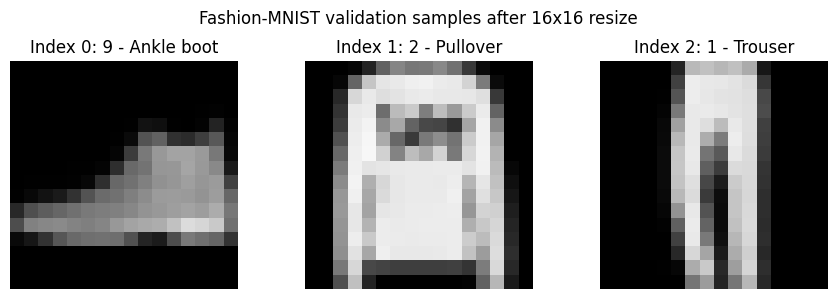

In [8]:
# Preserve the requested first three validation examples; no cherry-picking.
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for n, ax in enumerate(axes):
    image, label = dataset_val[n]
    ax.imshow(image.squeeze(0).numpy(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Index {n}: {label} - {dataset_val.classes[label]}')
    ax.axis('off')
fig.suptitle('Fashion-MNIST validation samples after 16x16 resize')
fig.tight_layout()
fig.savefig(OUT/'validation_samples.png', dpi=150)
plt.show()


## Task 2: Build and Train a Convolutional Neural Network


Create a Convolutional Neural Network class using ONE of the following constructors. Train the network using the provided code then provide a screenshot of your training cost and accuracy with your validation data.

Constructor using Batch Norm: 


In [9]:
class CNN_batch(nn.Module):

    # Constructor
    def __init__(self, out_1=16, out_2=32,number_of_classes=10):
        super(CNN_batch, self).__init__()
        self.cnn1 = nn.Conv2d(in_channels=1, out_channels=out_1, kernel_size=5, padding=2)
        self.conv1_bn = nn.BatchNorm2d(out_1)

        self.maxpool1=nn.MaxPool2d(kernel_size=2)

        self.cnn2 = nn.Conv2d(in_channels=out_1, out_channels=out_2, kernel_size=5, stride=1, padding=2)
        self.conv2_bn = nn.BatchNorm2d(out_2)

        self.maxpool2=nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(out_2 * 4 * 4, number_of_classes)
        self.bn_fc1 = nn.BatchNorm1d(10)

    # Prediction
    def forward(self, x):
        x = self.cnn1(x)
        x=self.conv1_bn(x)
        x = torch.relu(x)
        x = self.maxpool1(x)
        x = self.cnn2(x)
        x=self.conv2_bn(x)
        x = torch.relu(x)
        x = self.maxpool2(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x=self.bn_fc1(x)
        return x


Constructor for a regular Convolutional Neural Network:


In [10]:
class CNN(nn.Module):

    # Constructor
    def __init__(self, out_1=16, out_2=32,number_of_classes=10):
        super(CNN, self).__init__()
        self.cnn1 = nn.Conv2d(in_channels=1, out_channels=out_1, kernel_size=5, padding=2)
        self.maxpool1=nn.MaxPool2d(kernel_size=2)

        self.cnn2 = nn.Conv2d(in_channels=out_1, out_channels=out_2, kernel_size=5, stride=1, padding=2)
        self.maxpool2=nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(out_2 * 4 * 4, number_of_classes)

    # Prediction
    def forward(self, x):
        x = self.cnn1(x)
        x = torch.relu(x)
        x = self.maxpool1(x)
        x = self.cnn2(x)
        x = torch.relu(x)
        x = self.maxpool2(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        return x


Create the training and validation data loaders:


In [11]:
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(dataset=dataset_train, batch_size=100, shuffle=True,
                          generator=loader_generator, num_workers=0)
test_loader = DataLoader(dataset=dataset_val, batch_size=100, shuffle=False, num_workers=0)
assert len(train_loader) == 600 and len(test_loader) == 100
print('Training batches:', len(train_loader), 'Validation batches:', len(test_loader))


Training batches: 600 Validation batches: 100


Create the convolutional Neural Network object: 


In [12]:
torch.manual_seed(SEED)
model = CNN_batch(out_1=16, out_2=32, number_of_classes=10).to(device)
model.eval()
with torch.no_grad():
    probe = model(dataset_val[0][0].unsqueeze(0).to(device))
assert probe.shape == (1,10) and torch.isfinite(probe).all()
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print('16 -> 8 -> 4 spatial dimensions; classifier input: 32*4*4 = 512.')


CNN_batch(
  (cnn1): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv1_bn): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (cnn2): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2_bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=512, out_features=10, bias=True)
  (bn_fc1): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)
Trainable parameters: 18494
16 -> 8 -> 4 spatial dimensions; classifier input: 32*4*4 = 512.


Create the objects for the criterion and the optimizer named <code>criterion</code> and <code>optimizer</code>. Make the optimizer use SGD with a learning rate of 0.1 and the optimizer use Cross Entropy Loss


In [13]:
# CrossEntropyLoss consumes raw logits and integer class labels, not a second Softmax.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
print('Loss:', criterion, 'Optimizer: SGD, learning rate=0.1')


Loss: CrossEntropyLoss() Optimizer: SGD, learning rate=0.1


Here's the code used to train the model: 


In [14]:
# Preserve the course's five epochs, SGD 0.1, batch size 100 and full dataset.
start_time = time.perf_counter()
cost_list, accuracy_list, mean_loss_list, epoch_records = [], [], [], []
N_test = len(dataset_val)
n_epochs = 5
for epoch in range(n_epochs):
    epoch_start = time.perf_counter()
    cost, weighted_loss, seen = 0.0, 0.0, 0
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        z = model(x)
        loss = criterion(z, y)
        assert torch.isfinite(loss), 'Non-finite training loss'
        loss.backward()
        optimizer.step()
        cost += loss.item()
        weighted_loss += loss.item()*len(y)
        seen += len(y)
    assert seen == len(dataset_train)
    model.eval()
    correct, evaluated, validation_loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x_test, y_test in test_loader:
            x_test, y_test = x_test.to(device), y_test.to(device)
            z = model(x_test)
            yhat = z.argmax(dim=1)
            correct += (yhat == y_test).sum().item()
            evaluated += len(y_test)
            validation_loss_sum += criterion(z, y_test).item()*len(y_test)
    assert evaluated == N_test
    accuracy = correct/N_test
    cost_list.append(float(cost))
    mean_loss_list.append(float(weighted_loss/seen))
    accuracy_list.append(float(accuracy))
    record = {'epoch':epoch+1, 'training_examples':seen, 'validation_examples':evaluated,
              'training_batch_cost_sum':float(cost), 'training_mean_ce':float(weighted_loss/seen),
              'validation_mean_ce':float(validation_loss_sum/evaluated),
              'validation_correct':int(correct), 'validation_accuracy':float(accuracy),
              'seconds':time.perf_counter()-epoch_start}
    epoch_records.append(record)
    (OUT/'epoch_progress.json').write_text(json.dumps(epoch_records, indent=2))
    print(f'Epoch {epoch+1}/{n_epochs}: cost={cost:.4f}, train CE={record["training_mean_ce"]:.4f}, '
          f'validation accuracy={accuracy:.4%} ({correct}/{N_test}), '
          f'validation CE={record["validation_mean_ce"]:.4f}, seconds={record["seconds"]:.1f}', flush=True)
training_seconds = time.perf_counter()-start_time
assert len(cost_list) == len(accuracy_list) == n_epochs
print(f'Actual training and validation elapsed time: {training_seconds:.1f} seconds')


Epoch 1/5: cost=297.8554, train CE=0.4964, validation accuracy=85.8400% (8584/10000), validation CE=0.4468, seconds=32.5


Epoch 2/5: cost=210.1622, train CE=0.3503, validation accuracy=86.2100% (8621/10000), validation CE=0.4058, seconds=30.7


Epoch 3/5: cost=186.9291, train CE=0.3115, validation accuracy=87.9300% (8793/10000), validation CE=0.3438, seconds=32.4


Epoch 4/5: cost=175.1875, train CE=0.2920, validation accuracy=88.8100% (8881/10000), validation CE=0.3208, seconds=30.4


Epoch 5/5: cost=166.8329, train CE=0.2781, validation accuracy=88.0500% (8805/10000), validation CE=0.3444, seconds=31.0


Actual training and validation elapsed time: 157.8 seconds


You will use the following to plot the Cost and accuracy for each epoch for the training and testing data, respectively. 


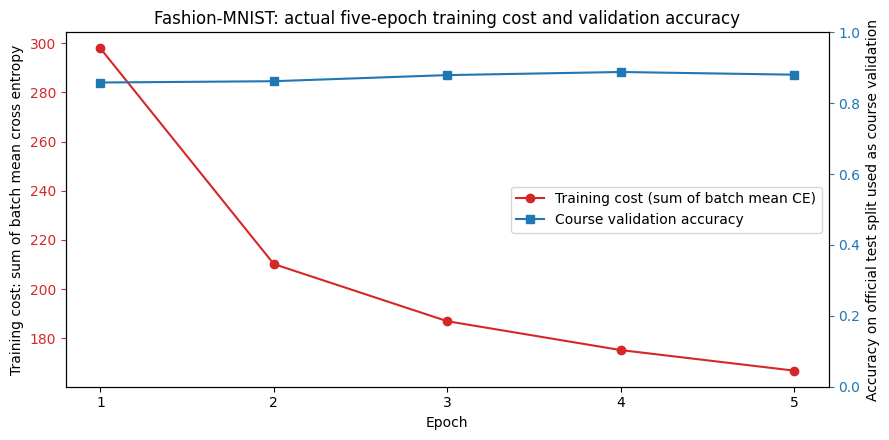

In [15]:
epochs = np.arange(1, n_epochs+1)
fig, ax1 = plt.subplots(figsize=(9,4.5))
ax1.plot(epochs, cost_list, 'o-', color='tab:red', label='Training cost (sum of batch mean CE)')
ax1.set(xlabel='Epoch', ylabel='Training cost: sum of batch mean cross entropy', xticks=epochs)
ax1.tick_params(axis='y', colors='tab:red')
ax2 = ax1.twinx()
ax2.plot(epochs, accuracy_list, 's-', color='tab:blue', label='Course validation accuracy')
ax2.set(ylabel='Accuracy on official test split used as course validation', ylim=(0,1))
ax2.tick_params(axis='y', colors='tab:blue')
ax1.set_title('Fashion-MNIST: actual five-epoch training cost and validation accuracy')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='center right')
fig.tight_layout()
fig.savefig(OUT/'training_cost_and_accuracy.png', dpi=150)
plt.show()


dataset: https://github.com/zalandoresearch/fashion-mnist


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a> 


<hr>


## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>


## Verified results and limitations

The following audit is calculated from the actual fixed fifth-epoch model. No grade, certificate, or production readiness is implied.

Class                  Precision  Recall  F1      Support
T-shirt/top            0.7874     0.8890  0.8351   1000
Trouser                0.9490     0.9860  0.9671   1000
Pullover               0.7595     0.8620  0.8075   1000
Dress                  0.9229     0.8740  0.8978   1000
Coat                   0.7605     0.8320  0.7947   1000
Sandal                 0.9599     0.9810  0.9703   1000
Shirt                  0.7961     0.4960  0.6112   1000
Sneaker                0.9525     0.9420  0.9472   1000
Bag                    0.9591     0.9840  0.9714   1000
Ankle boot             0.9629     0.9590  0.9609   1000


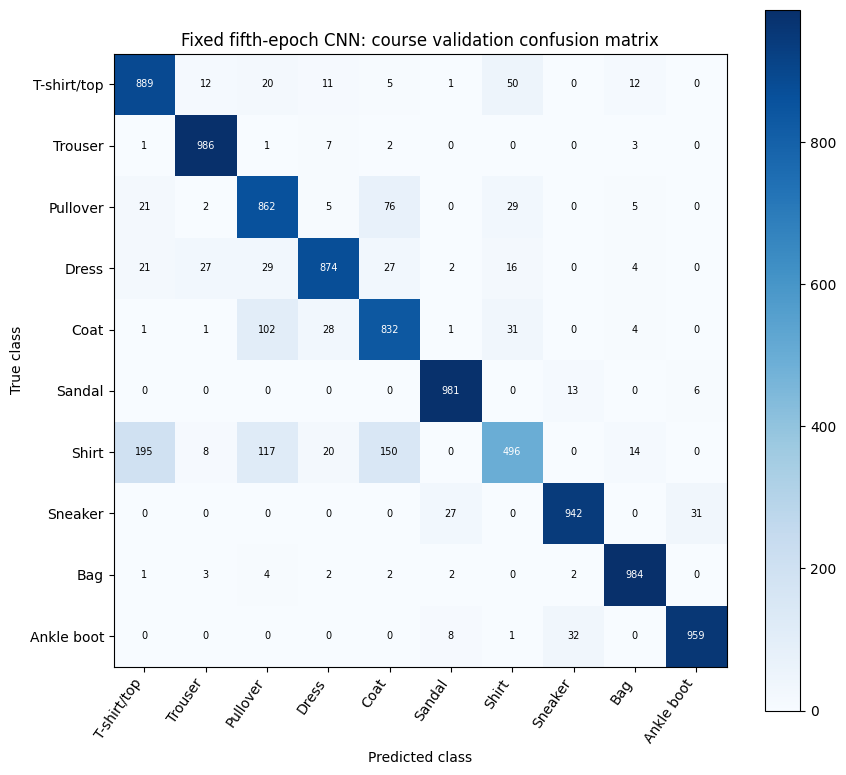

{
  "dataset": "Fashion-MNIST",
  "official_repository": "https://github.com/zalandoresearch/fashion-mnist",
  "download_mirror": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
  "source_integrity": {
    "train-images-idx3-ubyte.gz": {
      "bytes": 26421880,
      "md5": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
      "sha256": "3aede38d61863908ad78613f6a32ed271626dd12800ba2636569512369268a84"
    },
    "train-labels-idx1-ubyte.gz": {
      "bytes": 29515,
      "md5": "25c81989df183df01b3e8a0aad5dffbe",
      "sha256": "a04f17134ac03560a47e3764e11b92fc97de4d1bfaf8ba1a3aa29af54cc90845"
    },
    "t10k-images-idx3-ubyte.gz": {
      "bytes": 4422102,
      "md5": "bef4ecab320f06d8554ea6380940ec79",
      "sha256": "346e55b948d973a97e58d2351dde16a484bd415d4595297633bb08f03db6a073"
    },
    "t10k-labels-idx1-ubyte.gz": {
      "bytes": 5148,
      "md5": "bb300cfdad3c16e7a12a480ee83cd310",
      "sha256": "67da17c76eaffca5446c3361aaab5c3cd6d1c2608

**Actual final result:** 8,805/10,000 validation examples correct (88.05%); majority-class baseline 10.00%; macro F1 0.8763. Lowest measured recall: **Shirt**, 49.60%. The nominal 95% accuracy interval is 87.40%–88.67%, excluding test-reuse and distribution-shift effects. All 10,000 predictions match after weight reload; maximum logit difference 0.0. This is a course experiment, not evidence of performance on real customer photographs.

In [16]:
# Audit predictions and saved weights using the fixed final (fifth-epoch) model.
model.eval()
truth_parts, prediction_parts = [], []
with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu()
        truth_parts.append(labels.cpu())
        prediction_parts.append(predictions)
truth = torch.cat(truth_parts)
predictions = torch.cat(prediction_parts)
confusion = torch.bincount(truth*10+predictions, minlength=100).reshape(10,10)
correct_final = int((truth == predictions).sum())
assert int(confusion.sum()) == 10000 and correct_final == epoch_records[-1]['validation_correct']
recall = confusion.diag().float()/confusion.sum(dim=1)
precision = confusion.diag().float()/confusion.sum(dim=0).clamp(min=1)
f1 = 2*precision*recall/(precision+recall).clamp(min=1e-12)
print('Class                  Precision  Recall  F1      Support')
for i, name in enumerate(dataset_val.classes):
    print(f'{name:22s} {precision[i]:.4f}     {recall[i]:.4f}  {f1[i]:.4f}  {int(confusion[i].sum()):5d}')
fig, ax = plt.subplots(figsize=(9,8))
img = ax.imshow(confusion.numpy(), cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j,i,str(int(confusion[i,j])),ha='center',va='center',fontsize=7,
                color='white' if confusion[i,j] > confusion.max()/2 else 'black')
ax.set(xticks=range(10), yticks=range(10), xticklabels=dataset_val.classes,
       yticklabels=dataset_val.classes, xlabel='Predicted class', ylabel='True class',
       title='Fixed fifth-epoch CNN: course validation confusion matrix')
plt.setp(ax.get_xticklabels(),rotation=55,ha='right')
fig.colorbar(img, ax=ax)
fig.tight_layout(); fig.savefig(OUT/'confusion_matrix.png', dpi=150); plt.show()

weights_path = OUT/'fashion_cnn_batch.pth'
torch.save(model.state_dict(), weights_path)
loaded_model = CNN_batch(out_1=16,out_2=32,number_of_classes=10).to(device)
loaded_model.load_state_dict(torch.load(weights_path,map_location=device,weights_only=True))
loaded_model.eval()
reload_max_difference = 0.0
reload_prediction_matches = 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        before, after = model(images), loaded_model(images)
        reload_max_difference = max(reload_max_difference,float((before-after).abs().max()))
        reload_prediction_matches += int((before.argmax(1)==after.argmax(1)).sum())
assert reload_max_difference == 0 and reload_prediction_matches == 10000

majority_class = int(torch.bincount(dataset_train.targets).argmax())
majority_accuracy = float((truth==majority_class).float().mean())
total = len(truth); z=1.959963984540054; p=correct_final/total
denom=1+z*z/total; center=(p+z*z/(2*total))/denom
half=z*np.sqrt(p*(1-p)/total+z*z/(4*total*total))/denom
metrics = {'dataset':'Fashion-MNIST', 'official_repository':'https://github.com/zalandoresearch/fashion-mnist',
 'download_mirror':OFFICIAL_MIRROR, 'source_integrity':dataset_hashes,
 'training_examples':len(dataset_train), 'course_validation_examples':len(dataset_val),
 'original_image_shape':[1,28,28], 'transformed_image_shape':[1,16,16],
 'model':'CNN_batch (original IBM constructor)', 'seed':SEED, 'device':str(device),
 'batch_size':100, 'optimizer':'SGD', 'learning_rate':0.1, 'epochs':n_epochs,
 'epoch_records':epoch_records, 'elapsed_training_validation_seconds':training_seconds,
 'final_correct':correct_final, 'final_accuracy':p, 'majority_baseline_accuracy':majority_accuracy,
 'nominal_wilson_95_accuracy':[float(center-half),float(center+half)],
 'classes':dataset_val.classes, 'confusion_matrix':confusion.tolist(),
 'precision_per_class':precision.tolist(), 'recall_per_class':recall.tolist(), 'f1_per_class':f1.tolist(),
 'macro_f1':float(f1.mean()), 'reload_max_logit_difference':reload_max_difference,
 'reload_prediction_matches':reload_prediction_matches,
 'runtime':{'python':platform.python_version(),'torch':str(torch.__version__),
            'torchvision':torchvision.__version__,'numpy':np.__version__},
 'evaluation_limit':'Official test split repeatedly evaluated as course validation; no unseen deployment test.',
 'ai_assistance_disclosed':True}
(OUT/'execution_metrics.json').write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))
weakest = int(recall.argmin())
display(Markdown(f'**Actual final result:** {correct_final:,}/{total:,} validation examples correct '
 f'({p:.2%}); majority-class baseline {majority_accuracy:.2%}; macro F1 {float(f1.mean()):.4f}. '
 f'Lowest measured recall: **{dataset_val.classes[weakest]}**, {float(recall[weakest]):.2%}. '
 f'The nominal 95% accuracy interval is {center-half:.2%}–{center+half:.2%}, excluding test-reuse and distribution-shift effects. '
 f'All {reload_prediction_matches:,} predictions match after weight reload; maximum logit difference {reload_max_difference}. '
 'This is a course experiment, not evidence of performance on real customer photographs.'))


## Sources and submission

- Original IBM/Coursera Fashion-MNIST project notebook and unchanged CNN constructors.
- [Fashion-MNIST authors: data and checksums](https://github.com/zalandoresearch/fashion-mnist).
- [Official PyTorch CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

AI assistance is disclosed. Any assessment submission or personal authorship declaration must comply with the course rules.